# Identity-swap check from fish size: Shiv, `2024-02-20T21_56_26`

The frame-to-frame checks in `Tracking_comparison_Shiv_Kaden.ipynb` only catch **abrupt** swaps (centroid or area jumps). This notebook adds slower checks: the four fish differ in size, so a label that moves onto another fish, even gradually over a contact, ends up with the other fish's area.

Shiv's labels are ranked by size (1 largest, 2 second, 3 third, 0 smallest), which fits this test well. The typical sizes of neighbouring fish differ by about 1.4× (see below).

**Area used**: the mask area, with frames that fail any bad-frame check removed (untracked, overlap, fragmented, area jump, centroid jump). Those are frames where the area isn't a reliable size measure.

**Metric A: continuous size track** (works anywhere in the video)
* `s_i(t)`: rolling median of label *i*'s area over 2 s.
* `drift_i(t)`: how far `s_i` has moved from the label's own typical size, measured in half-gaps to the neighbouring fish's size. 0 = own size, ±1 = halfway, so it looks as much like the neighbour as like itself, ±2 = the neighbour's size.
* `swap_ij(t) = |log s_i/ref_i| + |log s_j/ref_j| − |log s_i/ref_j| − |log s_j/ref_i|`: positive when the two labels' sizes fit better exchanged. An **episode** is a run of `swap_ij > 0` lasting at least 1 s.

**Metric B: before vs after each encounter** (aimed at persistent swaps)
* An encounter is a run of frames where two fish's centroids are closer than half the sum of their typical lengths, close enough for the bodies to touch.
* Take each label's median area 1–11 s before and 1–11 s after the encounter.
* `enc_swap` is the same formula as `swap_ij`, but comparing after to before. It is positive when the two labels leave the encounter with each other's sizes.

`ref_i` is the label's median area over the whole video, which assumes the labels are correct most of the time.

In [1]:
import os, base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

os.chdir('/Volumes/Lenca_SSD/github/social_electric_fish')
import tracking_compare as tc
import identity_check as ic
%matplotlib inline
pd.set_option('display.precision', 2)

REC = '2024-02-20T21_56_26'
MP4 = 'data/elephantnose_21_56_26_tracking_final.mp4'          # Shiv's annotated video
MM_CACHE = 'figures/mask_metrics/elephantnose_21_56_26/metrics.pkl'
OUT = os.path.join('figures', 'identity_check', REC)
os.makedirs(OUT, exist_ok=True)

recs = tc.find_recordings()
row = recs[(recs.tracker == 'Shiv') & (recs.recording == REC)].iloc[0]
series, meta = ic.load_shiv_series(REC, row.path, MM_CACHE)
fps, FISH, NAME = meta['fps'], tc.FISH['Shiv'], tc.FISH_NAME['Shiv']
COLOR = dict(zip(FISH, tc.mm.PALETTE))        # the annotated video's colours: 1 pink, 2 green, 3 yellow, 0 blue
flags = tc.frame_flags(tc.load_metrics('Shiv', REC, row.path)['metrics'])

area = ic.valid_area(series, flags, FISH)
ref, length = ic.references(area, series, FISH)
w = int(ic.SMOOTH_S * fps)
smooth = area.rolling(w, center=True, min_periods=w // 2).median()
drift = ic.drift_index(smooth, ref)
score = ic.pair_swap_score(smooth, ref, FISH)

order = ref.sort_values(ascending=False).index
pd.DataFrame({'fish': [NAME[l] for l in order], 'typical area (px)': ref[order].values,
              'typical length (px)': length[order].values,
              'size ratio to next smaller': (ref[order] / ref[order].shift(-1)).values,
              '% frames with usable area': 100 * area[order].notna().mean().values})

,fish,typical area (px),typical length (px),size ratio to next smaller,% frames with usable area
0,1 largest,3462.0,219.09,1.38,94.51
1,2 second,2516.0,184.98,1.57,98.87
2,3 third,1598.0,140.34,1.39,97.51
3,0 smallest,1150.0,117.93,NaN,98.03


## A. Size over time

Thick line = 2 s rolling median of each label's area, dashed lines = the typical size of every fish. A swap would show as a label's line leaving its own dashed line and settling on another fish's line, for that label and its partner at the same time.

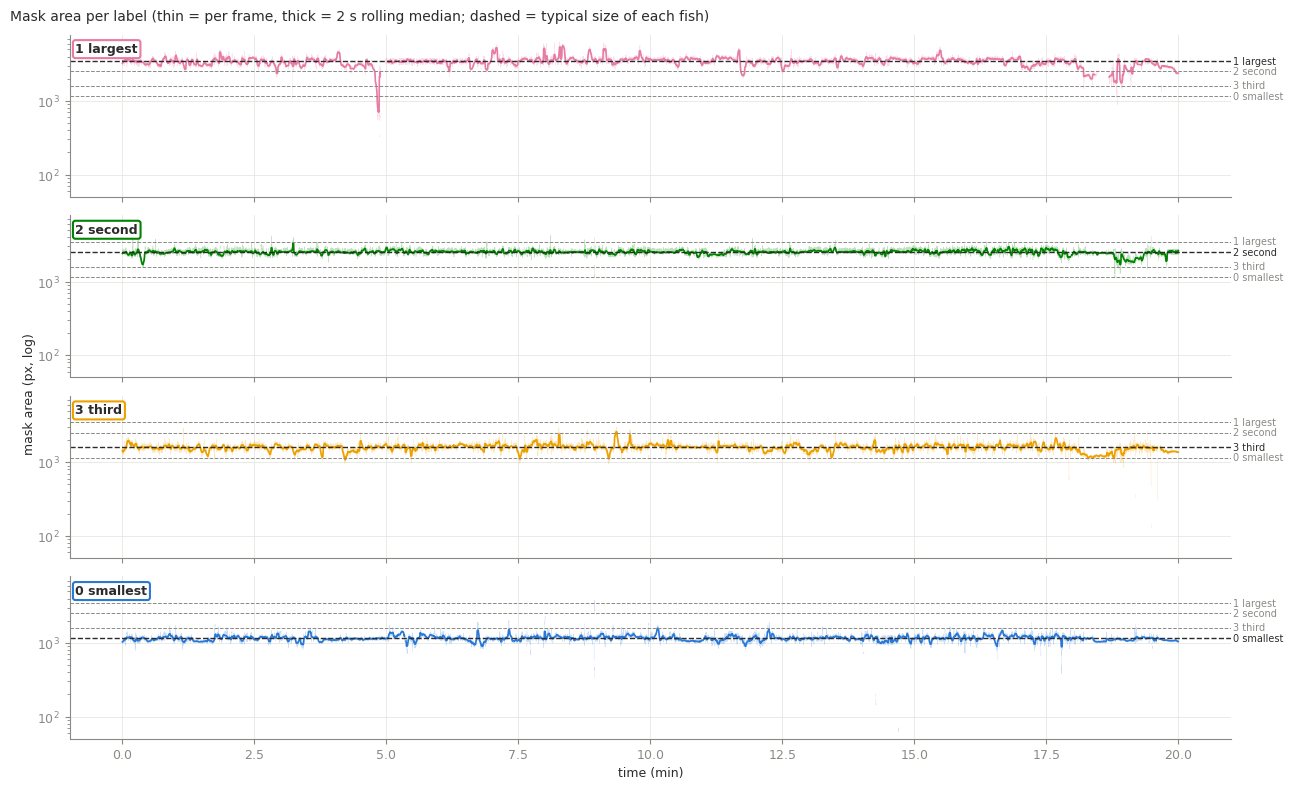

In [2]:
fig, axes = plt.subplots(len(FISH), 1, figsize=(13, 8), sharex=True, sharey=True)
t = area.index / fps / 60
for ax, lab in zip(axes, FISH):
    ax.plot(t, area[lab], color=COLOR[lab], lw=0.3, alpha=0.25, rasterized=True)
    ax.plot(t, smooth[lab], color=COLOR[lab], lw=1.2, rasterized=True)
    for other in FISH:
        ax.axhline(ref[other], color=tc.mm.INK if other == lab else tc.mm.MUTED,
                   lw=1 if other == lab else 0.7, ls='--')
        ax.text(1.002, ref[other], NAME[other], transform=ax.get_yaxis_transform(), fontsize=7,
                va='center', color=tc.mm.INK if other == lab else tc.mm.MUTED)
    tc.mm.fish_label(ax, lab, dict(fish_name=NAME, fish_color=COLOR))
    ax.set_yscale('log')
axes[-1].set_xlabel('time (min)')
fig.supylabel('mask area (px, log)', fontsize=9)
fig.suptitle('Mask area per label (thin = per frame, thick = 2 s rolling median; dashed = typical size of each fish)',
             x=0.01, ha='left', fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'area_tracks.png'), dpi=150)

**% of the video with |drift| > 1** (size closer to a neighbour than to its own): 1 largest 13.5%, 2 second 2.2%, 3 third 7.6%, 0 smallest 3.8%

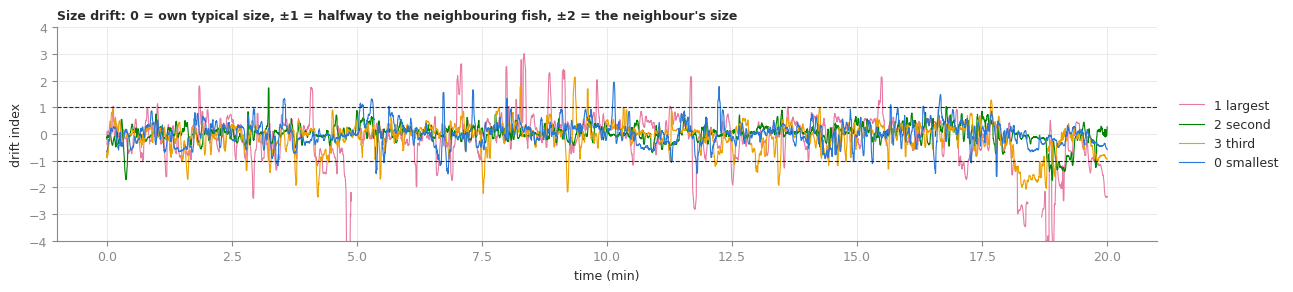

In [3]:
fig, ax = plt.subplots(figsize=(13, 3))
for lab in FISH:
    ax.plot(t, drift[lab], color=COLOR[lab], lw=0.8, label=NAME[lab], rasterized=True)
for y in (-1, 1):
    ax.axhline(y, color=tc.mm.INK, lw=0.8, ls='--')
ax.set_ylim(-4, 4)
ax.set_xlabel('time (min)')
ax.set_ylabel('drift index')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
ax.set_title('Size drift: 0 = own typical size, ±1 = halfway to the neighbouring fish, ±2 = the neighbour\'s size',
             loc='left', fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'drift_index.png'), dpi=150)
display(Markdown('**% of the video with |drift| > 1** (size closer to a neighbour than to its own): ' +
                 ', '.join(f'{NAME[l]} {100 * (drift[l].abs() > 1).mean():.1f}%' for l in FISH)))

### Metric A: swap episodes (`swap_ij > 0` for ≥ 1 s)

`area_i/ref_j` columns give the label's smoothed area at the peak, relative to each fish's typical size. In a real swap both `area_i/ref_j` and `area_j/ref_i` are close to 1, while `area_i/ref_i` and `area_j/ref_j` are not.

In [4]:
ep = ic.swap_episodes(score, smooth, ref, fps)
ep.to_csv(os.path.join(OUT, 'swap_episodes.csv'), index=False)
ep.dropna(axis=1, how='all')

,pair,start,end,peak_frame,duration_s,start_min,peak_score,mean_score,area_1/ref_1,area_1/ref_2,...,area_1/ref_3,area_3/ref_3,area_3/ref_1,area_1/ref_0,area_0/ref_0,area_0/ref_1,area_2/ref_3,area_3/ref_2,area_3/ref_0,area_0/ref_3
0,3-0,36690,36750,36721,1.22,12.23,0.17,0.06,NaN,NaN,...,NaN,0.89,NaN,NaN,1.34,NaN,NaN,NaN,1.23,0.96
1,2-3,27988,28103,28033,2.32,9.33,0.15,0.10,NaN,NaN,...,NaN,1.58,NaN,NaN,NaN,NaN,1.46,1.0,NaN,NaN
2,3-0,27597,27677,27619,1.62,9.20,0.13,0.10,NaN,NaN,...,NaN,0.70,NaN,NaN,1.07,NaN,NaN,NaN,0.97,0.77
3,1-3,14409,14593,14424,3.70,4.80,0.11,0.06,0.46,NaN,...,1.0,1.06,0.49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1-2,51512,51595,51549,1.68,17.17,0.08,0.05,0.76,1.05,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1-2,14389,14647,14487,5.18,4.80,0.07,0.06,0.26,0.36,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,3-0,55090,55141,55102,1.04,18.36,0.04,0.03,NaN,NaN,...,NaN,0.72,NaN,NaN,1.02,NaN,NaN,NaN,0.99,0.73
7,1-2,54617,54721,54681,2.10,18.21,0.04,0.02,0.63,0.87,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,3-0,40262,40314,40274,1.06,13.42,0.03,0.02,NaN,NaN,...,NaN,0.73,NaN,NaN,1.03,NaN,NaN,NaN,1.01,0.74
9,1-0,14488,14587,14550,2.00,4.83,0.03,0.01,0.21,NaN,...,NaN,NaN,NaN,0.65,1.01,0.34,NaN,NaN,NaN,NaN


## B. Before vs after every encounter

**373** encounters scored (4 without enough usable frames before or after). Real encounters with enc_swap > 0: **1**. Planted swaps detected (enc_swap > 0): **40 / 40** (lowest score 0.30).

,pair,start,end,start_min,duration_s,min_dist,before_i,after_i,before_j,after_j,enc_swap
46,1-3,13703,14393,4.57,13.82,94.38,3106.5,924.0,1457.0,1637.5,0.23
18,1-2,51786,51810,17.26,0.50,198.49,2823.0,3191.0,2690.5,2545.0,-0.10
19,1-2,51888,52015,17.30,2.56,192.90,2869.5,3191.0,2531.5,2684.0,-0.13
20,1-2,52185,52333,17.39,2.98,151.58,3107.0,3322.5,2441.0,2762.0,-0.24
373,3-0,54130,54177,18.04,0.96,68.20,1538.0,1326.0,1151.0,1152.0,-0.28
21,1-2,52408,52426,17.47,0.38,195.57,3187.0,3374.5,2556.0,2751.0,-0.29
26,1-2,53844,54081,17.95,4.76,170.67,3413.0,2891.0,2284.5,2483.5,-0.30
22,1-2,52466,52488,17.49,0.46,192.27,3202.0,3384.5,2485.0,2732.5,-0.32
372,3-0,54049,54092,18.02,0.88,114.48,1545.0,1361.0,1159.0,1161.0,-0.32
8,1-2,37898,37991,12.63,1.88,93.81,2958.0,3405.5,2522.0,2482.5,-0.32


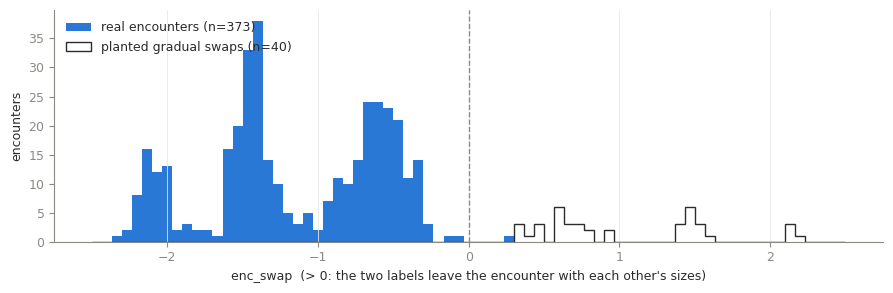

In [5]:
enc = ic.encounters(series, length, FISH, fps)
es = ic.encounter_swap(enc, area, fps)
es.to_csv(os.path.join(OUT, 'encounters.csv'), index=False)

# Positive control: plant a gradual (2 s) swap at 40 random encounters and rerun the test
ctrl = []
for e in enc.sample(40, random_state=0).itertuples():
    a = ic.inject_swap(area, series, e.i, e.j, e.start, 2.0, fps)
    ctrl.append(ic.encounter_swap(enc.loc[[e.Index]], a, fps).enc_swap.iloc[0])
ctrl = np.array(ctrl)

fig, ax = plt.subplots(figsize=(9, 3))
bins = np.linspace(-2.5, 2.5, 76)
ax.hist(es.enc_swap.dropna(), bins=bins, color=tc.TRACKER_COLOR['Shiv'], label=f'real encounters (n={es.enc_swap.notna().sum()})')
ax.hist(ctrl, bins=bins, histtype='step', lw=1.8, color=tc.mm.INK, label='planted gradual swaps (n=40)')
ax.axvline(0, color=tc.mm.MUTED, lw=1, ls='--')
ax.set_xlabel('enc_swap  (> 0: the two labels leave the encounter with each other\'s sizes)')
ax.set_ylabel('encounters')
ax.legend(loc='upper left')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'encounter_swap_hist.png'), dpi=150)
display(Markdown(f'**{es.enc_swap.notna().sum()}** encounters scored ({es.enc_swap.isna().sum()} without enough usable frames before or after). '
                 f'Real encounters with enc_swap > 0: **{(es.enc_swap > 0).sum()}**. '
                 f'Planted swaps detected (enc_swap > 0): **{(ctrl > 0).sum()} / {ctrl.size}** (lowest score {ctrl.min():.2f}).'))
es.sort_values('enc_swap', ascending=False).head(10)[
    ['pair', 'start', 'end', 'start_min', 'duration_s', 'min_dist', 'before_i', 'after_i', 'before_j', 'after_j', 'enc_swap']]

## Candidate frames, checked in the annotated video
The top candidates from A and B. Each row shows frames before, at and after the candidate (annotated-video colours: 1 pink, 2 green, 3 yellow, 0 blue).

,source,pair,frame,lo,hi,minute
0,A: swap episode,3-0,36721,36690,36750,12.24
1,A: swap episode,2-3,28033,27988,28103,9.34
2,A: swap episode,3-0,27619,27597,27677,9.21
3,A: swap episode,1-3,14424,14409,14593,4.81
4,A: swap episode,1-2,51549,51512,51595,17.18
5,B: encounter,1-2,51798,51786,51810,17.27
6,B: encounter,1-2,51951,51888,52015,17.32
7,B: encounter,1-3,14048,13703,14393,4.68


**A: swap episode, pair 3-0**: frames 36540 / 36721 / 36900

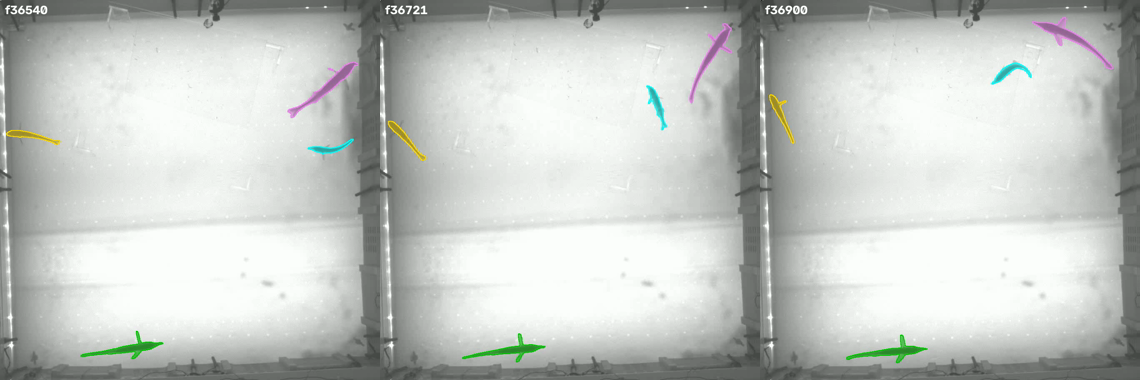

**A: swap episode, pair 2-3**: frames 27838 / 28033 / 28253

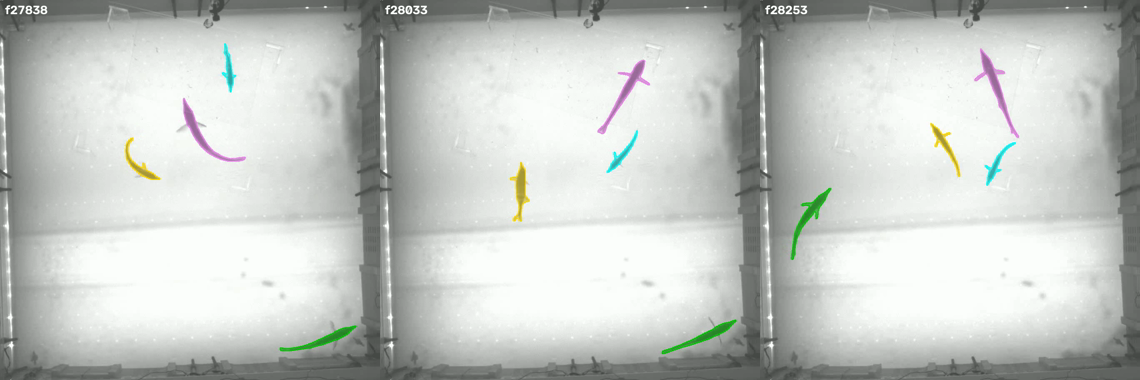

**A: swap episode, pair 3-0**: frames 27447 / 27619 / 27827

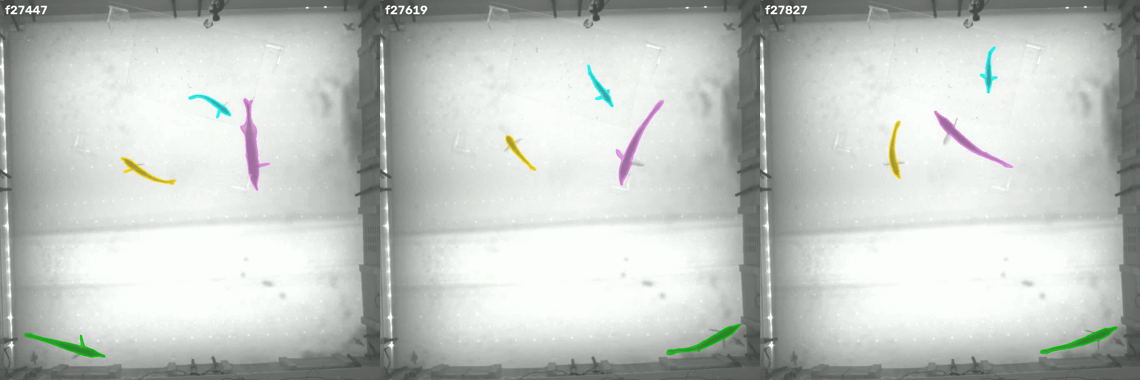

**A: swap episode, pair 1-3**: frames 14259 / 14424 / 14743

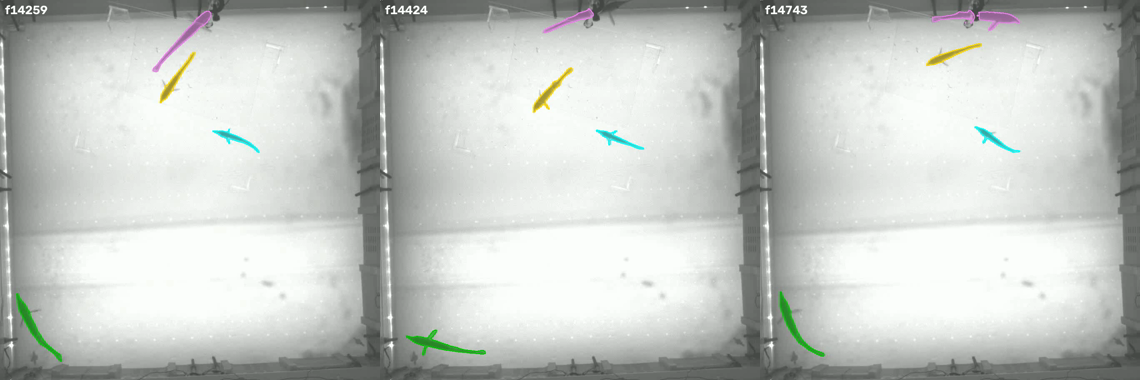

**A: swap episode, pair 1-2**: frames 51362 / 51549 / 51745

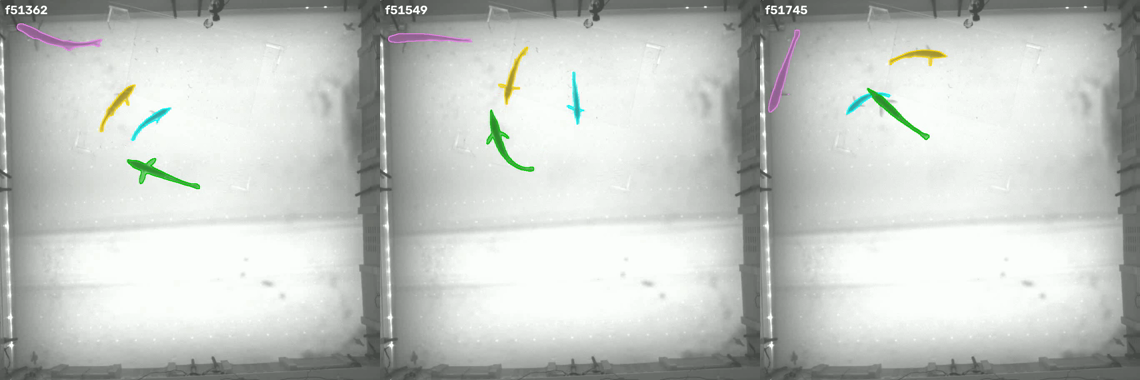

**B: encounter, pair 1-2**: frames 51636 / 51798 / 51960

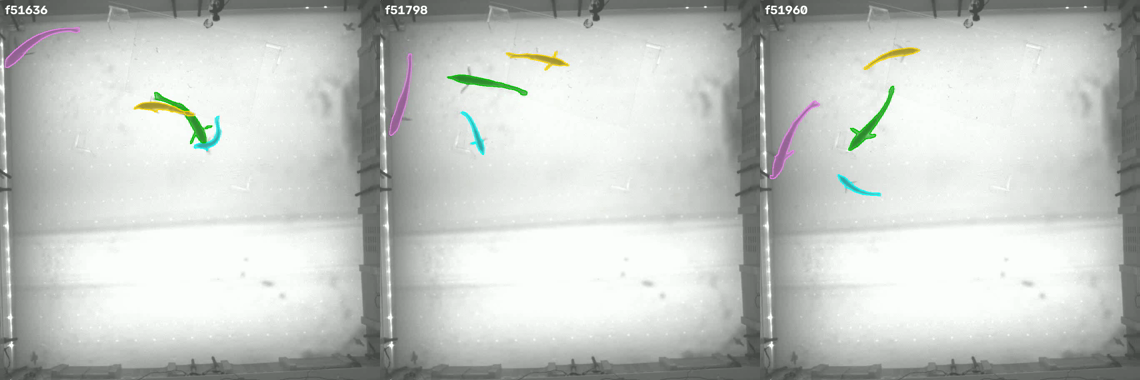

**B: encounter, pair 1-2**: frames 51738 / 51951 / 52165

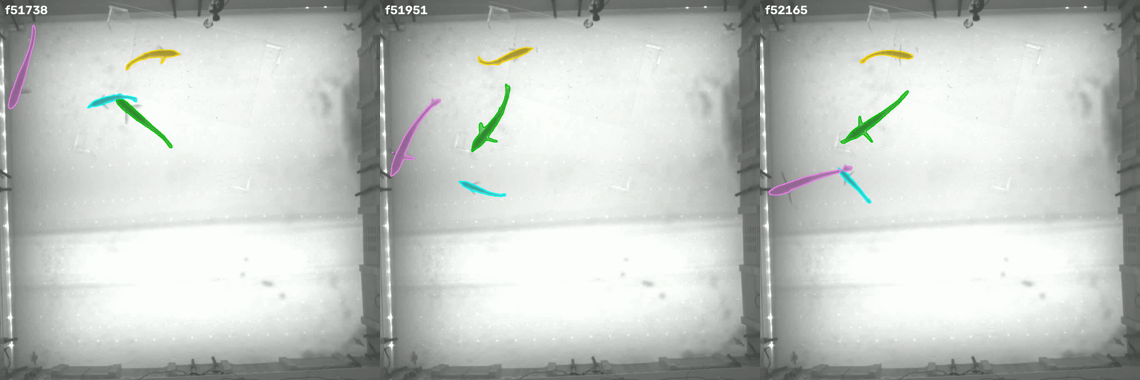

**B: encounter, pair 1-3**: frames 13553 / 14048 / 14543

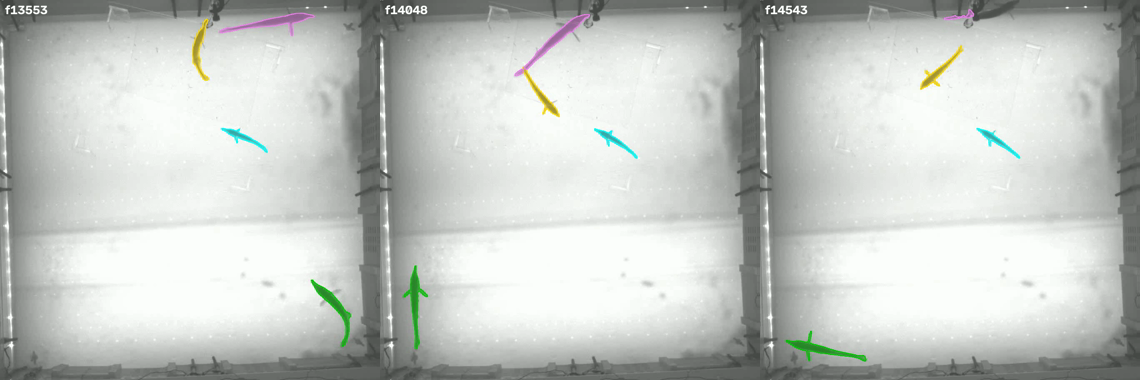

In [6]:
cand = pd.concat([
    ep.head(5).assign(source='A: swap episode', frame=ep.peak_frame, lo=ep.start, hi=ep.end)[['source', 'pair', 'frame', 'lo', 'hi']],
    es[es.enc_swap > -0.2].assign(source='B: encounter', frame=lambda d: (d.start + d.end) // 2, lo=es.start, hi=es.end)[['source', 'pair', 'frame', 'lo', 'hi']],
], ignore_index=True)
cand['minute'] = cand.frame / fps / 60
display(cand)
for c in cand.itertuples():
    frames = [max(c.lo - 150, 0), c.frame, min(c.hi + 150, meta['n_frames'] - 1)]
    png = ic.contact_sheet(MP4, frames, os.path.join(OUT, f'candidate_{c.source[0]}_{c.pair}_{c.frame}.png'), fps, width=380)
    display(Markdown(f'**{c.source}, pair {c.pair}**: frames {frames[0]} / {frames[1]} / {frames[2]}'))
    display(Image(png, width=1100))

### Visual verdict (checked by eye, 2026-10-29)
| candidate | frames | what happens | swap? |
|---|---|---|---|
| A + B, pair 1–3, ~min 4.6–4.9 | 13 703–14 647 | label 1 (pink) swims along the top wall under the hanging apparatus; its mask shrinks to ~0.2–0.5× while partly hidden, and yellow stays yellow | no: occlusion by the apparatus |
| A, pair 2–3, min 9.3 | 27 988–28 103 | label 3 (yellow) grows to fish-2 size while turning with fins spread; green is far away at the bottom | no: posture or fins |
| A, pair 3–0, min 12.2 | 36 690–36 750 | label 0 (blue) grows ~1.3× with fins spread; yellow is on the far left | no: posture or fins |
| A, pair 3–0, min 9.2 | 27 597–27 677 | label 3 (yellow) shrinks to 0.7× while curled in a turn; blue is normal and far away | no: posture |
| A + B, pair 1–2, min 17.2–17.3 | 51 512–52 015 | label 1 (pink) runs along the top-left wall, partly hidden; green is mid-tank and unchanged | no: occlusion at the wall |
| size track only, min 18–19.6 | ~54 000–58 800 | labels 3, 1 and 2 all shrink (3 down to fish-0 size) while the fish sit along the top wall; label 0 stays mid-tank and normal | no: the same top-wall effect |

The remaining A episodes have peak scores below 0.1, a slight preference for swapping that is within size noise.

**Lesson**: apparent area depends on position. Along the top wall, fish lose 10–15% of their area, and more where they pass under the apparatus. That's the main source of false alarms; normalising area by position, or ignoring wall frames, would sharpen both metrics.

## Summary for this video
* **No size evidence of an identity swap.** No encounter ends with the labels carrying each other's sizes. The only positive `enc_swap` (+0.23, pair 1–3) is label 1 being partly hidden at the top wall, and the planted gradual swaps all score at least +0.30.
* The continuous track flags 10 short episodes and a longer drift late in the video. All of the ones checked are explained by the fish being partly hidden at the top wall or by posture and fins, and in each only **one** label deviates, while a swap moves both.
* **Limits**: a swap that reverts within about 1 s is invisible to B and too short for A (it would usually show up as a centroid jump instead). A swap between fish of similar size can't be seen this way at all; here every neighbouring pair differs by ≥1.38×. And if a swap lasted for most of the video, `ref_i` itself would be wrong.